# 01 · Primer análisis con la API

Se miden Dq, tau, alpha y f(alpha) de una traza dentro de un dominio cuadrado. Los metros son unidades de modelo sin ubicación geográfica. Se declaran los parámetros antes del cálculo. La tabla descriptiva conserva las estimaciones; el diagnóstico examina su respaldo por separado.

In [1]:
from pathlib import Path
import os
import sys
import time
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from shapely.geometry import LineString, box
from pyproj import CRS

started_wall, started_cpu = time.perf_counter(), time.process_time()
repository = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/musa").is_dir())
sys.path.insert(0, str(repository / "src"))
sys.path.insert(0, str(repository / "scripts"))
from musa import MUSA, ScalingOptions, assess_lineament_scaling, write_scaling_reports
crs = CRS.from_proj4("+proj=eqc +R=6371000 +units=m +no_defs +type=crs")
lines = [LineString([(1000, 1500), (9000, 6500)])]
domain = box(0, 0, 10000, 10000)
scales = np.geomspace(10, 1000, 16)
model = MUSA.from_line_geometries(lines, domain, crs, q_values=[0, 1, 2])
output = Path(os.environ.get("MUSA_NOTEBOOK_OUTPUT_ROOT", repository / "outputs/notebooks")) / "01_first_analysis"
output.mkdir(parents=True, exist_ok=True)
def save_figure(figure, name):
    target = output / (name + ".png")
    figure.savefig(target, dpi=120, bbox_inches="tight")
    display(Image(filename=str(target)))
    plt.close(figure)
print("Synthetic inputs; unlocated model metres. Outputs:", output.name)


Synthetic inputs; unlocated model metres. Outputs: 01_first_analysis


## Mapa y cálculo descriptivo

Se usan q=0…4 y cinco escalas descriptivas; el filtro R² es 0,9.

,q,Dq,tau,alpha,f_alpha
0,0.0,1.0,-1.0,1.0,1.0
1,1.0,1.0,0.0,1.0,1.0
2,2.0,1.0,1.0,1.0,1.0
3,3.0,1.0,2.0,1.0,1.0
4,4.0,1.0,3.0,1.0,1.0


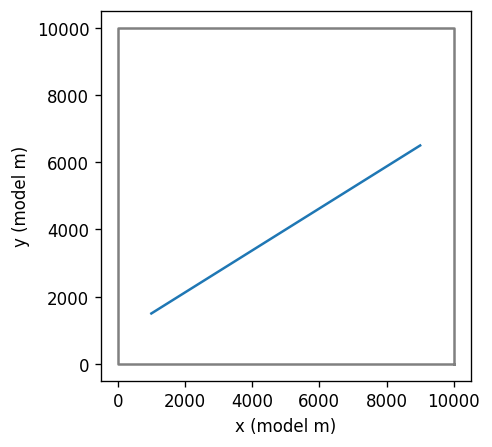

In [2]:
model = MUSA.from_line_geometries(lines, domain, crs, q_values=np.arange(5.))
result = model.run_analysis(resolutions_m=[1000, 500, 250, 125, 62.5], min_r2=.9)
table = pd.DataFrame(dict(q=result.q, Dq=result.dq, tau=result.tau, alpha=result.alpha, f_alpha=result.f_alpha))
assert result.accepted_count == 5
np.testing.assert_allclose(result.tau, (result.q-1)*result.dq, atol=1e-10)
table.to_csv(output / "per_q.csv", index=False)
display(table)
figure, ax = plt.subplots(figsize=(5, 4))
ax.plot(*domain.exterior.xy, color="gray")
ax.plot(*lines[0].xy)
ax.set(xlabel="x (model m)", ylabel="y (model m)", aspect="equal")
save_figure(figure, "map")

## Las cuatro magnitudes por q

La línea uniforme tiene Dq cercano a uno en este diseño. Cada punto f(alpha(q)) se muestra frente a q. La forma conjunta f(alpha) requiere controles adicionales.

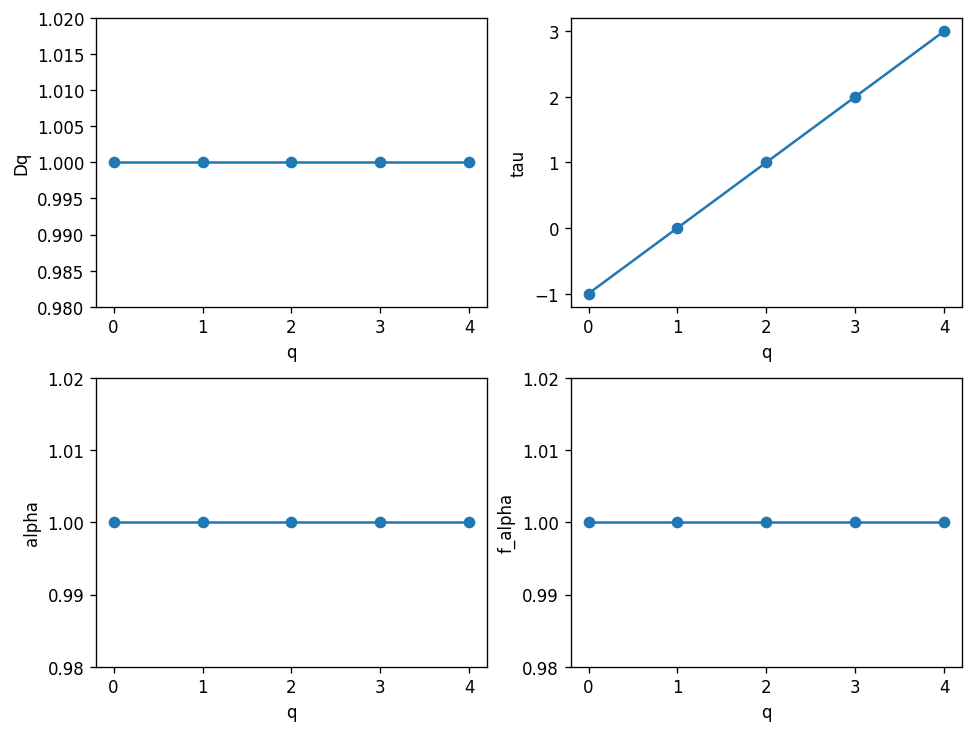

,q,dimension,tau,alpha,f_alpha,status
0,0.0,0.986590,-0.986590,0.977690,0.986590,compatible_finite_range
1,1.0,0.991085,0.000000,0.991085,0.991085,compatible_finite_range
2,2.0,0.993307,0.993307,0.995056,0.996804,compatible_finite_range
3,3.0,0.994721,1.989442,0.996992,1.001532,compatible_finite_range
4,4.0,0.995662,2.986985,0.997992,1.004981,compatible_finite_range


In [3]:
figure, axes = plt.subplots(2, 2, figsize=(8, 6), constrained_layout=True)
for ax, field in zip(axes.ravel(), ["Dq", "tau", "alpha", "f_alpha"]):
    ax.plot(table.q, table[field], "o-")
    ax.set(xlabel="q", ylabel=field)
    if np.ptp(table[field]) < 1e-6:
        middle = float(table[field].mean())
        ax.set_ylim(middle-.02, middle+.02)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
save_figure(figure, "four_observables")
report = assess_lineament_scaling(model, scales, ScalingOptions(1, renyi_order_policy="inform_q0_q2"))
write_scaling_reports(output / "assessment", [report])
display(pd.DataFrame(report["q_results"])[["q", "dimension", "tau", "alpha", "f_alpha", "status"]])

In [4]:
metrics = dict(wall_seconds=time.perf_counter()-started_wall,
               cpu_seconds_kernel=time.process_time()-started_cpu)
(output / "execution.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print(json.dumps(metrics))


{"wall_seconds": 3.414369699999952, "cpu_seconds_kernel": 3.40625}
